##作業1

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2023s 12us/step
訓練資料 X_train 形狀: (50000, 32, 32, 3)
訓練標籤 y_train 形狀: (50000, 1)
測試資料 X_test 形狀: (10000, 32, 32, 3)
測試標籤 y_test 形狀: (10000, 1)


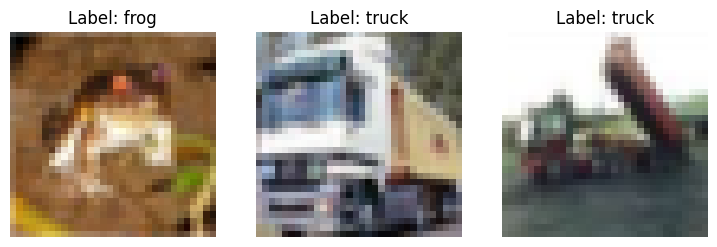

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     2,097,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,122,186 (8.10 MB)

 Trainable params: 2,122,186 (8.10 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 82s 257ms/step - accuracy: 0.4297 - loss: 1.5991 - val_accuracy: 0.5693 - val_loss: 1.2429
Epoch 2/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 78s 248ms/step - accuracy: 0.5985 - loss: 1.1437 - val_accuracy: 0.6360 - val_loss: 1.0473
Epoch 3/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 81s 247ms/step - accuracy: 0.6536 - loss: 0.9880 - val_accuracy: 0.6502 - val_loss: 1.0095
Epoch 4/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 77s 245ms/step - accuracy: 0.6986 - loss: 0.8640 - val_accuracy: 0.6827 - val_loss: 0.9184
Epoch 5/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 82s 245ms/step - accuracy: 0.7343 - loss: 0.7668 - val_accuracy: 0.6900 - val_loss: 0.8991
Epoch 6/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 87s 263ms/step - accuracy: 0.7603 - loss: 0.6887 - val_accuracy: 0.7031 - val_loss: 0.8831
Epoch 7/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 77s 246ms/step - accuracy: 0.7956 - loss: 0.5932 - val_accuracy: 0.7104 - val_loss: 0.8794
Epoch 8/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 82s 247ms/step - accuracy: 0.8191 - loss: 0

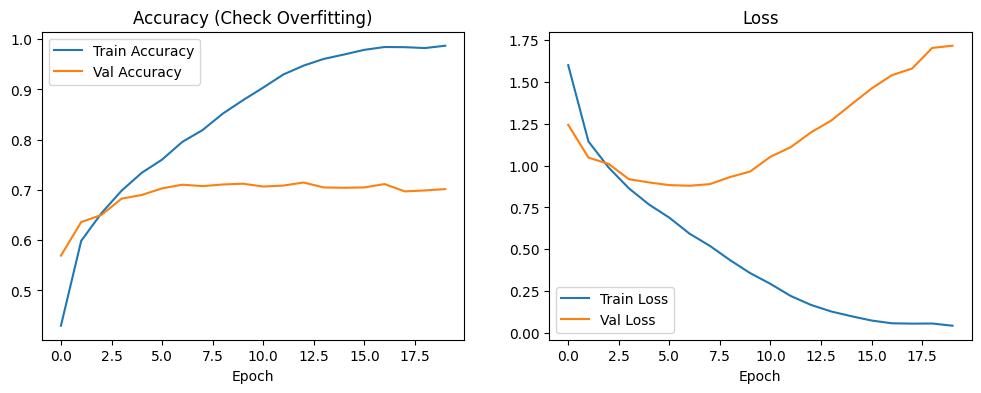

測試資料集準確率: 70.06%
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step


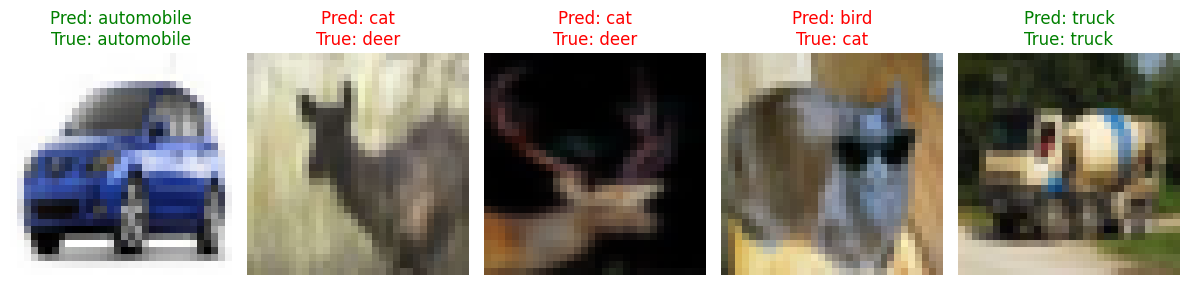

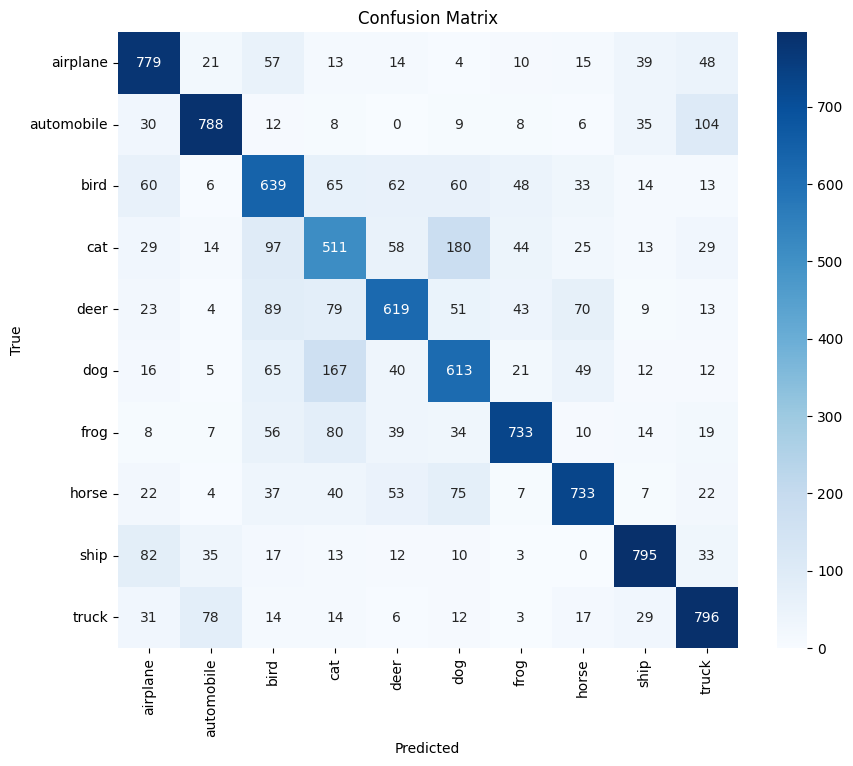

模型已成功儲存為 hw4_1_model.keras


interactive(children=(IntSlider(value=0, description='index', max=999), Button(description='Run Interact', sty…

<function __main__.predict_test_image(index)>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import confusion_matrix
import seaborn as sns
import ipywidgets as widgets
from IPython.display import display

# 1. 資料預處理
(X_train, y_train), (X_test, y_test) = cifar10.load_data()

# CIFAR-10 的 10 個類別名稱 (對應課本 p.2-81)
class_names = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

print("訓練資料 X_train 形狀:", X_train.shape)
print("訓練標籤 y_train 形狀:", y_train.shape)
print("測試資料 X_test 形狀:", X_test.shape)
print("測試標籤 y_test 形狀:", y_test.shape)

# 呈現至少三張訓練圖片及其真實標籤名稱
plt.figure(figsize=(9, 3))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(X_train[i])
    plt.title(f"Label: {class_names[y_train[i][0]]}")
    plt.axis('off')
plt.show()

# 正規化 (像素縮放到 0~1) 與 One-hot Encoding
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0
y_train_onehot = to_categorical(y_train, 10)
y_test_onehot = to_categorical(y_test, 10)

# 2. 建立神經網路模型 (參考課本 p.2-83 第 2 題架構範例)
model = Sequential([
    Conv2D(32, (3, 3), padding='same', input_shape=(32, 32, 3), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),
    Conv2D(64, (3, 3), padding='same', activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),
    Flatten(),
    Dense(512, activation='relu'),
    Dense(10, activation='softmax')
])

model.summary()

# 3. 編譯與訓練神經網路模型
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

history = model.fit(
    X_train, y_train_onehot,
    batch_size=128,
    epochs=20,
    validation_split=0.2,
    verbose=1
)

# 4. 以折線圖顯示訓練過程的 loss & accuracy
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Accuracy (Check Overfitting)')
plt.xlabel('Epoch')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Loss')
plt.xlabel('Epoch')
plt.legend()
plt.show()

# 5. 評估模型準確率
test_loss, test_acc = model.evaluate(X_test, y_test_onehot, verbose=0)
print(f"測試資料集準確率: {test_acc * 100:.2f}%")

# 6. 進行預測與展示測試圖片
predictions = model.predict(X_test)
predicted_classes = np.argmax(predictions, axis=1)

plt.figure(figsize=(12, 5))
for i in range(5):
    idx = np.random.randint(0, len(X_test))
    plt.subplot(1, 5, i + 1)
    plt.imshow(X_test[idx])
    pred_name = class_names[predicted_classes[idx]]
    true_name = class_names[y_test[idx][0]]
    color = 'green' if predicted_classes[idx] == y_test[idx][0] else 'red'
    plt.title(f"Pred: {pred_name}\nTrue: {true_name}", color=color)
    plt.axis('off')
plt.tight_layout()
plt.show()

# 7. 混淆矩陣 (Confusion Matrix)
cm = confusion_matrix(y_test, predicted_classes)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

# 8. 儲存完整模型 (.keras 格式)
model.save("hw4_1_model.keras")
print("模型已成功儲存為 hw4_1_model.keras")

# 9. 結合 interact_manual 呈現測試圖片的預測結果 (參考課本 16.6 p.2-81)
def predict_test_image(index):
    img = X_test[index]
    plt.figure(figsize=(3, 3))
    plt.imshow(img)
    plt.axis('off')
    plt.show()

    pred_prob = model.predict(np.expand_dims(img, axis=0))
    pred_idx = np.argmax(pred_prob)
    print(f"真實標籤: {class_names[y_test[index][0]]}")
    print(f"預測結果: {class_names[pred_idx]} (信心機率: {pred_prob[0][pred_idx]*100:.2f}%)")

widgets.interact_manual(predict_test_image, index=widgets.IntSlider(min=0, max=999, step=1, value=0))